# 12 · Animación esquemática de la trayectoria

Generaremos una animación 2D que representa la posición del motor sobre una pista. No es una reconstrucción molecular ni representa las dos cabezas de kinesina.

> **ProteinMotorSim 0.1.1** · Ejemplo educativo. Las tasas predeterminadas del modelo son ilustrativas y no representan todavía una parametrización experimental validada.

## Preparación del entorno

Esta celda localiza automáticamente la raíz del repositorio e incorpora `src/` a la ruta de importación. Instala antes las dependencias con `python -m pip install -e ".[dev,viz]"` y selecciona el kernel `Python (ProteinMotorSim)`.

In [1]:
from pathlib import Path
import sys

# Busca la raíz del proyecto desde el directorio actual o sus carpetas padre.
_candidates = [Path.cwd(), *Path.cwd().parents]
PROJECT_ROOT = next(
    (path for path in _candidates if (path / "pyproject.toml").exists() and (path / "src").is_dir()),
    None,
)

if PROJECT_ROOT is None:
    raise RuntimeError(
        "No se encontró ProteinMotorSim. Abre JupyterLab desde la carpeta raíz "
        "del proyecto o desde su carpeta notebooks/."
    )

sys.path.insert(0, str(PROJECT_ROOT / "src"))
print(f"Proyecto detectado: {PROJECT_ROOT}")

Proyecto detectado: /home/zix/ProteinMotorSim


## 1. Ejecutar una trayectoria corta

In [2]:
from IPython.display import HTML, display

from protein_motor_sim import Environment, GillespieSimulator, Kinesin1
from protein_motor_sim.visualization.animation import animate_trajectory

trajectory = GillespieSimulator().run(
    Kinesin1(), Environment(atp_concentration=1.0e-3),
    t_max=0.08, seed=99,
)
print("Número de fotogramas:", len(trajectory.times_s))

Número de fotogramas: 17


## 2. Construir y mostrar la animación

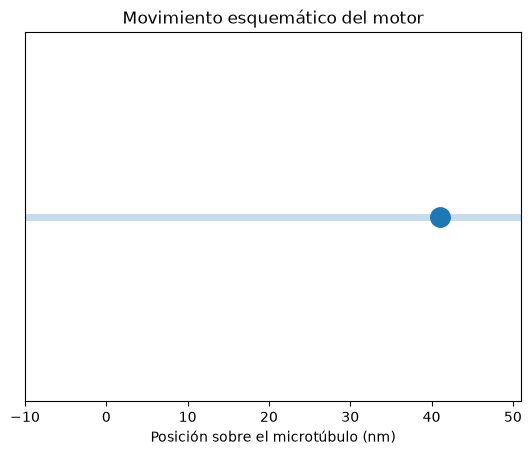

In [3]:
animation = animate_trajectory(trajectory, interval_ms=180)
display(HTML(animation.to_jshtml()))

## 3. Guardado opcional

Para exportar a GIF se necesita Pillow; para MP4 suele requerirse FFmpeg. La animación mostrada en el notebook no depende de esos formatos de exportación.

In [4]:
# Opcional, si Pillow está instalado:
# animation.save(PROJECT_ROOT / "results" / "trajectory.gif", writer="pillow")